In [1]:
!pip -q install pandas numpy scikit-learn matplotlib

import io, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
warnings.filterwarnings("ignore")

uploaded = files.upload()
csvs = {}
for name, content in uploaded.items():
    if name.lower().endswith(".csv"):
        csvs[os.path.basename(name).lower()] = pd.read_csv(io.BytesIO(content))

def get_csv(prefix, required=True):
    matches = [v for k, v in csvs.items() if k.startswith(prefix)]
    if not matches:
        if required:
            raise ValueError(f"Please upload {prefix}.csv")
        return None
    return matches[0]

train_df = get_csv("train")
test_df = get_csv("test")
sample_df = get_csv("sample", required=False)

print("Train:", train_df.shape, " Test:", test_df.shape)
print("Sample:", None if sample_df is None else sample_df.shape)
display(train_df.head())

Saving sample.csv to sample.csv
Saving test.csv to test.csv
Saving train.csv to train.csv
Train: (1567, 51)  Test: (180, 50)
Sample: (20, 2)


,Procurement_ID,tender_country,tender_size,tender_supplyType,tender_procedureType,tender_nationalProcedureType,tender_mainCpv,tender_addressOfImplementation_nuts,tender_addressOfImplementation_country,tender_year,...,tender_lots_count,tender_publications_count,buyer_buyerType,buyer_mainActivities,buyer_nuts,buyer_country,cpvcat,source,Final_Price_EUR,Estimated_Price_EUR
0,80c5-a54d65027e57-00cf9c7d-c48e-44e2,CZ,BELOW_THE_THRESHOLD,WORKS,OPEN,Otevrene,44163120.0,NaN,NaN,2014.0,...,1.0,2.0,OTHER,"GAS_AND_HEAT_PRODUCTION,ELECTRICITY,OTHER",CZ080,CZ,44,This competition uses data from the Open Tende...,390290.40,402003.00
1,8430-f10b3f60cadc-031e3670-90a2-4032,CZ,BELOW_THE_THRESHOLD,SUPPLIES,OPEN,Otevrene,34928480.0,NaN,NaN,2014.0,...,1.0,2.0,REGIONAL_AUTHORITY,"GENERAL_PUBLIC_SERVICES,HOUSING_AND_COMMUNITY_...",CZ053,CZ,34,NaN,60981.86,31512.04
2,837a-a5672f1608e6-0381a518-930b-4190,CZ,BELOW_THE_THRESHOLD,WORKS,OPEN,Otevrene,44200000.0,NaN,NaN,2014.0,...,1.0,2.0,PUBLIC_BODY,"HEALTH,SOCIAL_PROTECTION,RECREATION_CULTURE_AN...",NaN,CZ,44,NaN,496687.95,595332.79
3,9ead-4673248286e0-05e20440-4029-45ff,CZ,BELOW_THE_THRESHOLD,SUPPLIES,OPEN,Otevrene,34111100.0,NaN,NaN,2014.0,...,1.0,2.0,REGIONAL_AUTHORITY,"OTHER,GENERAL_PUBLIC_SERVICES",CZ042,CZ,34,NaN,51898.72,54692.21
4,9362-77a5577dc039-065d321c-dd47-4ca8,CZ,BELOW_THE_THRESHOLD,SERVICES,OPEN,Otevrene,71250000.0,NaN,NaN,2014.0,...,1.0,9.0,NATIONAL_AUTHORITY,"ECONOMIC_AND_FINANCIAL_AFFAIRS,GENERAL_PUBLIC_...",CZ01,CZ,71,NaN,48128.18,66775.39


In [2]:
required_cols = ["Procurement_ID", "Final_Price_EUR", "Estimated_Price_EUR"]
missing = [c for c in required_cols if c not in train_df.columns]
if missing:
    raise ValueError(f"Missing required training columns: {missing}")

train_df["Final_Price_EUR"] = pd.to_numeric(train_df["Final_Price_EUR"], errors="coerce")
train_df["Estimated_Price_EUR"] = pd.to_numeric(train_df["Estimated_Price_EUR"], errors="coerce")

model_df = train_df.dropna(subset=["Final_Price_EUR", "Estimated_Price_EUR"]).copy()
model_df = model_df[model_df["Estimated_Price_EUR"] > 0].copy()
model_df["price_overrun_ratio"] = (
    model_df["Final_Price_EUR"] - model_df["Estimated_Price_EUR"]
) / model_df["Estimated_Price_EUR"]

# Proxy label: final price exceeded estimated price
model_df["risk_proxy"] = (model_df["price_overrun_ratio"] > 0).astype(int)

print("Usable labelled rows:", len(model_df))
print("Proxy outcome distribution:")
display(model_df["risk_proxy"].value_counts().rename(index={0:"No price overrun",1:"Price overrun"}).to_frame("records"))
print("Proxy positive rate:", round(model_df["risk_proxy"].mean()*100, 2), "%")

display(model_df[["Procurement_ID","Estimated_Price_EUR","Final_Price_EUR","price_overrun_ratio","risk_proxy"]].head())

Usable labelled rows: 1563
Proxy outcome distribution:


,records
risk_proxy,
No price overrun,1401
Price overrun,162


Proxy positive rate: 10.36 %


,Procurement_ID,Estimated_Price_EUR,Final_Price_EUR,price_overrun_ratio,risk_proxy
0,80c5-a54d65027e57-00cf9c7d-c48e-44e2,402003.00,390290.40,-0.029136,0
1,8430-f10b3f60cadc-031e3670-90a2-4032,31512.04,60981.86,0.935192,1
2,837a-a5672f1608e6-0381a518-930b-4190,595332.79,496687.95,-0.165697,0
3,9ead-4673248286e0-05e20440-4029-45ff,54692.21,51898.72,-0.051077,0
4,9362-77a5577dc039-065d321c-dd47-4ca8,66775.39,48128.18,-0.279253,0


In [3]:
# Candidate pre-award fields available in this Kaggle file.
candidate_features = [
    "tender_country", "tender_size", "tender_supplyType",
    "tender_procedureType", "tender_nationalProcedureType",
    "tender_mainCpv", "tender_year", "tender_fundingProgrammes",
    "tender_npwp_reasons", "tender_bidDeadline",
    "tender_estimatedStartDate", "tender_estimatedCompletionDate",
    "tender_estimatedDurationInYears", "tender_estimatedDurationInMonths",
    "tender_estimatedDurationInDays", "tender_isEUFunded", "tender_isDps",
    "tender_isElectronicAuction", "tender_isCentralProcurement",
    "tender_isJointProcurement", "tender_isOnBehalfOf",
    "tender_isFrameworkAgreement", "tender_isCoveredByGpa",
    "tender_hasLots", "tender_estimatedPrice_currency",
    "tender_description_length", "tender_personalRequirements_length",
    "tender_economicRequirements_length", "tender_technicalRequirements_length",
    "tender_documents_count", "tender_awardCriteria_count",
    "tender_corrections_count", "tender_onBehalfOf_count",
    "tender_lots_count", "tender_publications_count",
    "buyer_buyerType", "buyer_mainActivities", "buyer_nuts",
    "buyer_country", "cpvcat", "Estimated_Price_EUR"
]
features = [c for c in candidate_features if c in model_df.columns and c in test_df.columns]

# Convert date fields to numeric calendar components, then remove raw strings.
date_cols = [c for c in ["tender_bidDeadline","tender_estimatedStartDate","tender_estimatedCompletionDate"] if c in model_df.columns and c in test_df.columns]
for frame in [model_df, test_df]:
    for col in date_cols:
        dt = pd.to_datetime(frame[col], errors="coerce")
        frame[col + "_year"] = dt.dt.year
        frame[col + "_month"] = dt.dt.month
        frame.drop(columns=[col], inplace=True, errors="ignore")
        for suffix in ["_year", "_month"]:
            newcol = col + suffix
            if newcol not in features:
                features.append(newcol)
    features = [f for f in features if f not in date_cols]

# Keep only features present in both datasets.
features = [c for c in features if c in model_df.columns and c in test_df.columns]
X = model_df[features].copy()
y = model_df["risk_proxy"].astype(int)

# Identify numeric and categorical columns
for col in X.columns:
    if X[col].dtype == "object":
        # Convert numeric-looking columns where appropriate
        converted = pd.to_numeric(X[col], errors="coerce")
        if converted.notna().mean() > 0.85:
            X[col] = converted

numeric_features = X.select_dtypes(include=["number","bool"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

print("Number of model features:", len(features))
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)
display(X.head())

Number of model features: 44
Numeric: ['tender_mainCpv', 'tender_year', 'tender_npwp_reasons', 'tender_estimatedDurationInYears', 'tender_estimatedDurationInMonths', 'tender_estimatedDurationInDays', 'tender_description_length', 'tender_personalRequirements_length', 'tender_economicRequirements_length', 'tender_technicalRequirements_length', 'tender_documents_count', 'tender_awardCriteria_count', 'tender_corrections_count', 'tender_onBehalfOf_count', 'tender_lots_count', 'tender_publications_count', 'cpvcat', 'Estimated_Price_EUR', 'tender_bidDeadline_year', 'tender_bidDeadline_month', 'tender_estimatedStartDate_year', 'tender_estimatedStartDate_month', 'tender_estimatedCompletionDate_year', 'tender_estimatedCompletionDate_month']
Categorical: ['tender_country', 'tender_size', 'tender_supplyType', 'tender_procedureType', 'tender_nationalProcedureType', 'tender_fundingProgrammes', 'tender_isEUFunded', 'tender_isDps', 'tender_isElectronicAuction', 'tender_isCentralProcurement', 'tender_i

,tender_country,tender_size,tender_supplyType,tender_procedureType,tender_nationalProcedureType,tender_mainCpv,tender_year,tender_fundingProgrammes,tender_npwp_reasons,tender_estimatedDurationInYears,...,buyer_nuts,buyer_country,cpvcat,Estimated_Price_EUR,tender_bidDeadline_year,tender_bidDeadline_month,tender_estimatedStartDate_year,tender_estimatedStartDate_month,tender_estimatedCompletionDate_year,tender_estimatedCompletionDate_month
0,CZ,BELOW_THE_THRESHOLD,WORKS,OPEN,Otevrene,44163120.0,2014.0,NaN,NaN,NaN,...,CZ080,CZ,44,402003.00,2014,9,2015.0,6.0,2015.0,8.0
1,CZ,BELOW_THE_THRESHOLD,SUPPLIES,OPEN,Otevrene,34928480.0,2014.0,NaN,NaN,NaN,...,CZ053,CZ,34,31512.04,2014,8,NaN,NaN,NaN,NaN
2,CZ,BELOW_THE_THRESHOLD,WORKS,OPEN,Otevrene,44200000.0,2014.0,NaN,NaN,NaN,...,NaN,CZ,44,595332.79,2014,5,NaN,NaN,NaN,NaN
3,CZ,BELOW_THE_THRESHOLD,SUPPLIES,OPEN,Otevrene,34111100.0,2014.0,NaN,NaN,NaN,...,CZ042,CZ,34,54692.21,2014,9,2014.0,10.0,2016.0,12.0
4,CZ,BELOW_THE_THRESHOLD,SERVICES,OPEN,Otevrene,71250000.0,2014.0,NaN,NaN,NaN,...,CZ01,CZ,71,66775.39,2015,1,2015.0,2.0,2019.0,12.0


In [4]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=5))
        ]), categorical_features)
    ],
    remainder="drop"
)

cart = DecisionTreeClassifier(
    criterion="gini", max_depth=4, min_samples_leaf=15,
    class_weight="balanced", random_state=42
)
pipeline = Pipeline([("prep", preprocessor), ("cart", cart)])

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
pipeline.fit(X_train, y_train)

pred = pipeline.predict(X_valid)
prob = pipeline.predict_proba(X_valid)[:, 1]

print(classification_report(y_valid, pred, target_names=["No price overrun","Price overrun"], zero_division=0))
print("Confusion matrix:\n", confusion_matrix(y_valid, pred))
if y_valid.nunique() == 2:
    print("ROC-AUC:", round(roc_auc_score(y_valid, prob), 3))

                  precision    recall  f1-score   support

No price overrun       0.96      0.63      0.76       350
   Price overrun       0.19      0.76      0.31        41

        accuracy                           0.65       391
       macro avg       0.58      0.70      0.54       391
    weighted avg       0.88      0.65      0.72       391

Confusion matrix:
 [[222 128]
 [ 10  31]]
ROC-AUC: 0.766


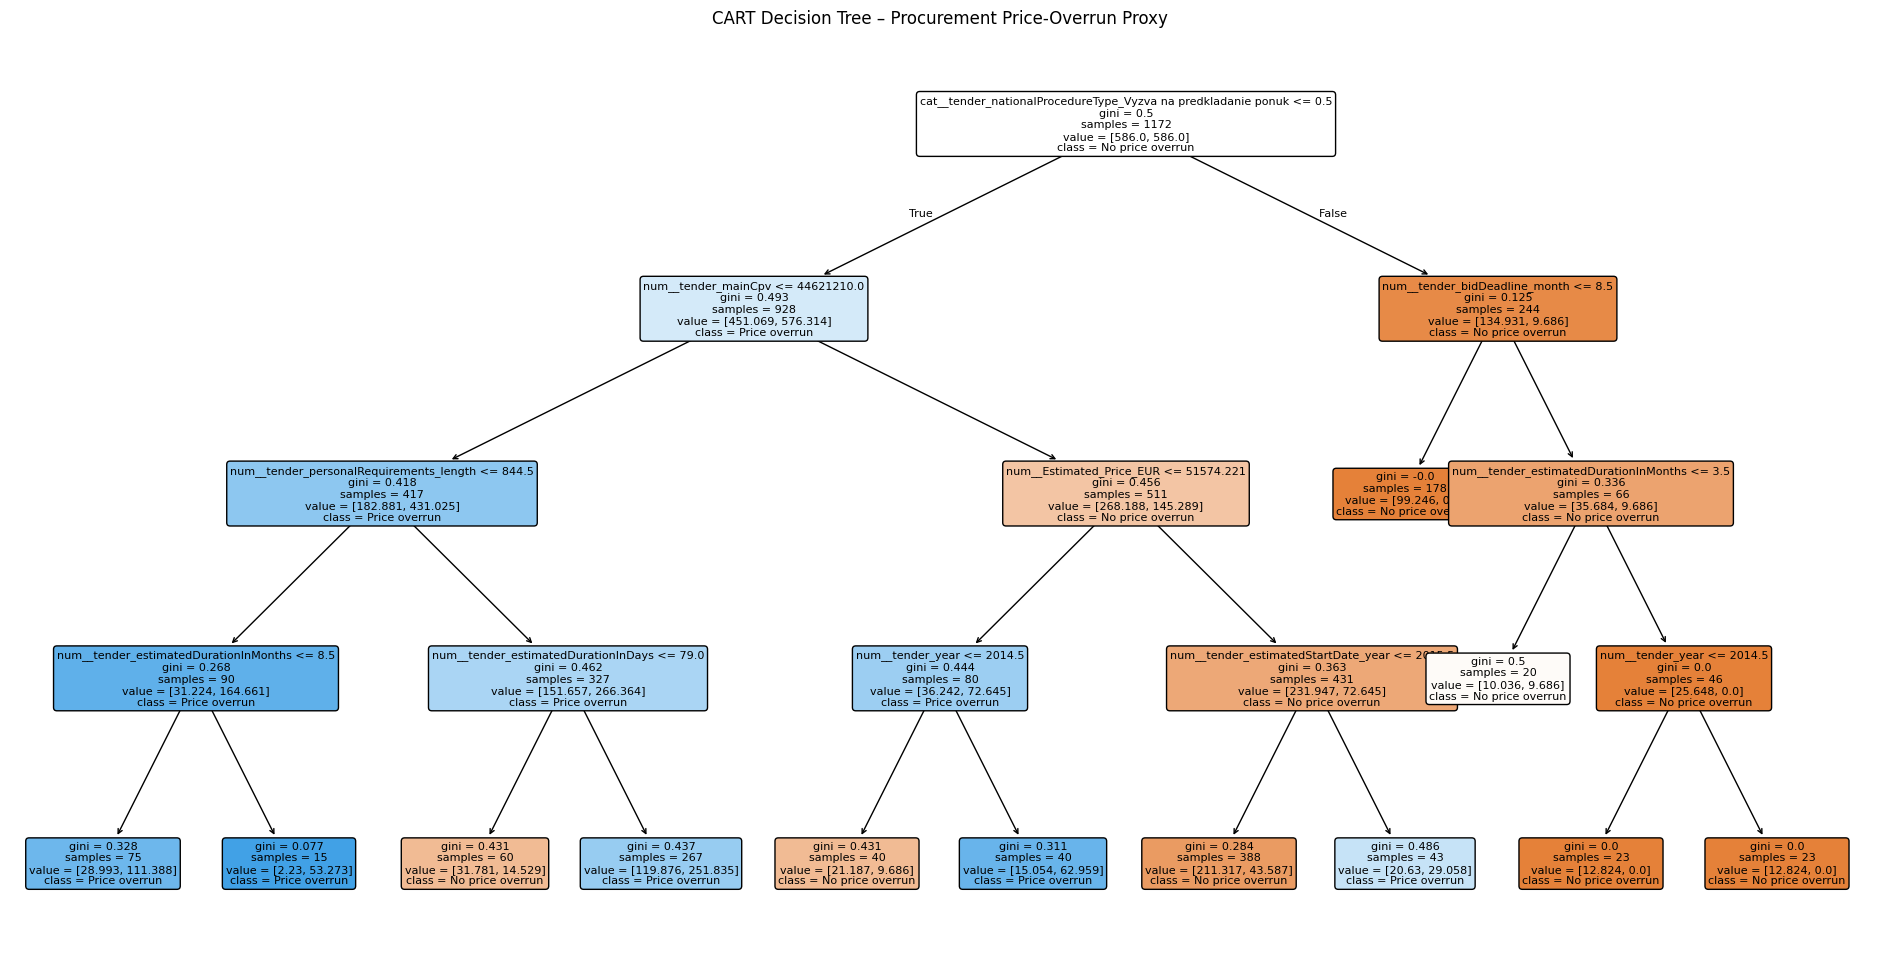

|--- cat__tender_nationalProcedureType_Vyzva na predkladanie ponuk <= 0.500
|   |--- num__tender_mainCpv <= 44621210.000
|   |   |--- num__tender_personalRequirements_length <= 844.500
|   |   |   |--- num__tender_estimatedDurationInMonths <= 8.500
|   |   |   |   |--- class: 1
|   |   |   |--- num__tender_estimatedDurationInMonths >  8.500
|   |   |   |   |--- class: 1
|   |   |--- num__tender_personalRequirements_length >  844.500
|   |   |   |--- num__tender_estimatedDurationInDays <= 79.000
|   |   |   |   |--- class: 0
|   |   |   |--- num__tender_estimatedDurationInDays >  79.000
|   |   |   |   |--- class: 1
|   |--- num__tender_mainCpv >  44621210.000
|   |   |--- num__Estimated_Price_EUR <= 51574.221
|   |   |   |--- num__tender_year <= 2014.500
|   |   |   |   |--- class: 0
|   |   |   |--- num__tender_year >  2014.500
|   |   |   |   |--- class: 1
|   |   |--- num__Estimated_Price_EUR >  51574.221
|   |   |   |--- num__tender_estimatedStartDate_year <= 2015.500
|   |   |   |

In [5]:
feature_names = pipeline.named_steps["prep"].get_feature_names_out()
tree_model = pipeline.named_steps["cart"]

plt.figure(figsize=(24, 12))
plot_tree(
    tree_model, feature_names=feature_names,
    class_names=["No price overrun","Price overrun"],
    filled=True, rounded=True, fontsize=8
)
plt.title("CART Decision Tree – Procurement Price-Overrun Proxy")
plt.show()

rules = export_text(tree_model, feature_names=list(feature_names), decimals=3)
print(rules)

,importance
cat__tender_nationalProcedureType_Vyzva na predkladanie ponuk,0.295331
num__tender_mainCpv,0.290144
num__Estimated_Price_EUR,0.140715
num__tender_estimatedStartDate_year,0.067982
num__tender_personalRequirements_length,0.052684
num__tender_estimatedDurationInDays,0.052025
num__tender_year,0.051389
num__tender_estimatedDurationInMonths,0.036182
num__tender_bidDeadline_month,0.013548
num__tender_awardCriteria_count,0.000000


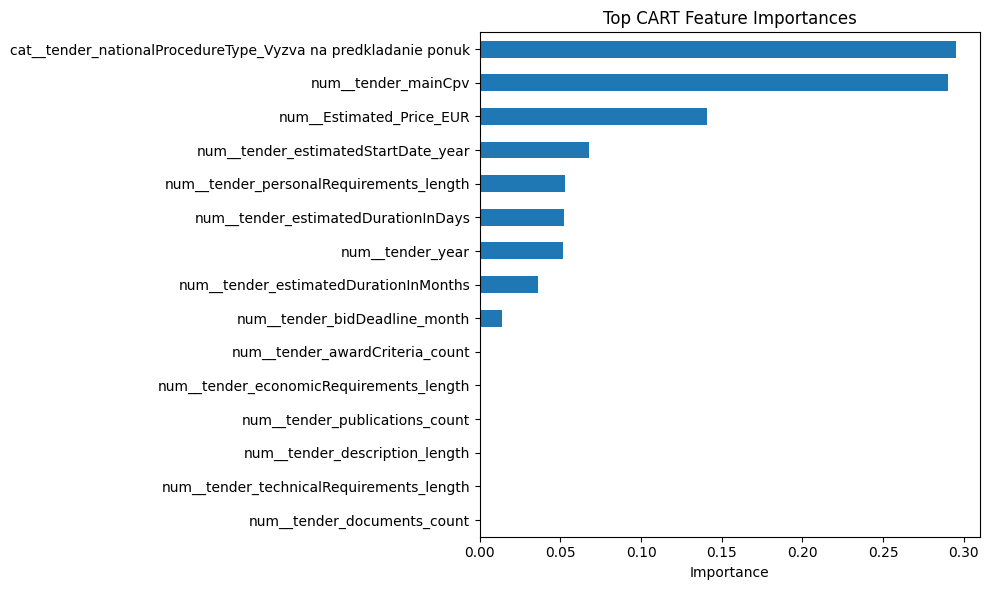

In [6]:
importance = pd.Series(tree_model.feature_importances_, index=feature_names).sort_values(ascending=False)
display(importance.head(20).rename("importance").to_frame())

plt.figure(figsize=(10,6))
importance.head(15).sort_values().plot(kind="barh")
plt.title("Top CART Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [7]:
# Align test features to training columns and apply same basic numeric conversion
X_test_kaggle = test_df.copy()
for col in features:
    if col not in X_test_kaggle.columns:
        X_test_kaggle[col] = np.nan
    if col in numeric_features:
        X_test_kaggle[col] = pd.to_numeric(X_test_kaggle[col], errors="coerce")
X_test_kaggle = X_test_kaggle[features]

test_scores = pipeline.predict_proba(X_test_kaggle)[:, 1]
scored_test = test_df[["Procurement_ID"]].copy() if "Procurement_ID" in test_df else pd.DataFrame(index=test_df.index)
scored_test["model_screening_score"] = test_scores
scored_test["screening_band"] = pd.cut(
    test_scores, bins=[-0.001,0.33,0.66,1.001],
    labels=["Lower score","Moderate score","Higher score"]
)
scored_test = scored_test.sort_values("model_screening_score", ascending=False)
display(scored_test.head(25))

scored_test.to_csv("kaggle_procurement_test_risk_scores.csv", index=False)
with open("cart_procurement_decision_rules.txt","w",encoding="utf-8") as f:
    f.write("CART rules for price-overrun proxy\n")
    f.write("Not a corruption classifier or finding. Human review required.\n\n")
    f.write(rules)

from google.colab import files
files.download("kaggle_procurement_test_risk_scores.csv")
files.download("cart_procurement_decision_rules.txt")

,Procurement_ID,model_screening_score,screening_band
146,a833-45824d87d753-134a118e-68b9-4f1a,0.807029,Higher score
149,94c9-92bbcaed52d3-1e7faf6f-2666-4fff,0.807029,Higher score
74,9783-2e065ceb67bb-5303b0de-cdfb-4650,0.807029,Higher score
83,8e29-6d69b0446ace-689c4ae4-e584-40e7,0.807029,Higher score
147,a3c7-c6301661a162-160cfd39-83d6-40bd,0.793468,Higher score
144,b9d3-a083ae684397-0e897cb5-5510-4704,0.793468,Higher score
143,afd5-12b9889f0b4c-0b8d708e-9b1d-44fb,0.793468,Higher score
142,8836-d5bb5e143c98-0945ef28-773c-4bd6,0.793468,Higher score
141,a34f-8ccf0d839c08-02e34162-8d47-4edc,0.793468,Higher score
136,9741-d350f2d94d21-eb7933e3-9e8f-4905,0.793468,Higher score


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>